# 09 — Diễn giải mô hình & kiểm tra độ bền (Interpretability & Robustness)

**Người phụ trách:** Nguyễn Hùng Phúc — Interpretability & Robustness Lead (kế thừa vai trò Feature Engineering ở Bài 3)

**Câu hỏi của notebook này:** mô hình dự đoán `price_per_m2` dựa vào *điều gì*, *sai ở đâu* và *có thể cải thiện bằng feature nào có bằng chứng*?

| Mục | Nội dung | Bàn giao |
|---|---|---|
| 1 | Nạp dữ liệu/mô hình đã bàn giao, kiểm tra tái lập | — |
| 2 | Hệ số mô hình tuyến tính (Ridge) + khoảng tin cậy bootstrap | `reports/linear_coefficients.csv` |
| 3 | Permutation importance + impurity importance (RandomForest) | `reports/importance_table.csv` |
| 4 | Đối chiếu với correlation/VIF của Tuấn | (bảng trong notebook) |
| 5 | Lỗi theo `khu_vuc_nhom`, `loai_bds`, khoảng diện tích | `reports/error_by_segment.csv` |
| 6 | Đề xuất feature mới — chỉ giữ nếu CV chứng minh | `reports/feature_candidates_cv.csv` |
| 7 | 3–5 kết luận nghiệp vụ có bằng chứng | `reports/model_findings.md` |

**Nguyên tắc làm việc (không phá luồng của Tuấn/Mạnh):**
- Không refit lại preprocessing ngoài Pipeline; không dùng `gia`, `gia_goc`, `price_per_m2` làm feature.
- Chọn feature mới **chỉ bằng CV trên train** (cùng `KFold(5, shuffle, random_state=42)` với Mạnh). Test **không** tham gia quyết định giữ/bỏ feature.
- Đơn vị: **triệu VNĐ/m²** (trừ khi ghi khác). Residual = thực tế − dự đoán; dương nghĩa là mô hình **dự đoán thấp hơn** giá rao.
- Mọi phát hiện là quan hệ **dự báo**, không phải quan hệ nhân quả.

In [1]:
from pathlib import Path
import ast, json, sys, warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
here = Path.cwd().resolve()
project_root = here.parent if here.name == 'notebooks' else here
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.modeling.preprocess import (
    CATEGORICAL_FEATURES, CATEGORY_REFERENCE_LEVELS, MODEL_FEATURES,
    NUMERIC_FEATURES, TARGET, build_model_pipeline,
)

DATA_DIR = project_root / 'data' / 'processed'
REPORTS_DIR = project_root / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'
MODELS_DIR = project_root / 'models'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
M = 1e6  # đổi VNĐ/m² -> triệu VNĐ/m²
print(f'Project root: {project_root}')
print(f'Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__}')

Project root: /home/claude/Final_Project_Nhom_22-24-main
Python 3.12.3 | scikit-learn 1.8.0


## 1. Nạp dữ liệu và mô hình đã bàn giao

Dùng đúng hai split của Tuấn (`model_train_raw.csv`, `model_test_raw.csv`) và mô hình cuối của Mạnh (`models/best_model.joblib`).

File joblib được lưu bằng một phiên bản scikit-learn cụ thể; nếu máy chạy khác phiên bản và không nạp được, notebook **dựng lại đúng mô hình đó** từ siêu tham số đã khoá trong `reports/model_hyperparameters.csv` (cùng `random_state=42`) rồi **kiểm tra lại MAE test khớp `reports/model_comparison.csv`**. Nhờ vậy phần diễn giải luôn gắn với đúng mô hình Mạnh đã chọn.

In [2]:
train_df = pd.read_csv(DATA_DIR / 'model_train_raw.csv', encoding='utf-8-sig')
test_df = pd.read_csv(DATA_DIR / 'model_test_raw.csv', encoding='utf-8-sig')
assert not set(train_df['link_nguon']) & set(test_df['link_nguon']), 'train/test trùng link_nguon'

X_train, y_train = train_df[MODEL_FEATURES].copy(), train_df[TARGET].copy()
X_test, y_test = test_df[MODEL_FEATURES].copy(), test_df[TARGET].copy()
assert not {'gia', 'gia_goc', TARGET} & set(X_train.columns), 'Leakage: giá nằm trong X'
print(f'Train {X_train.shape} | Test {X_test.shape} | Feature: {MODEL_FEATURES}')

comparison = pd.read_csv(REPORTS_DIR / 'model_comparison.csv', encoding='utf-8-sig').set_index('model')
hyper = pd.read_csv(REPORTS_DIR / 'model_hyperparameters.csv', encoding='utf-8-sig').set_index('model')
rf_params = json.loads(hyper.loc['RandomForest', 'best_params'])
ridge_alpha = json.loads(hyper.loc['Ridge', 'best_params'])['model__alpha']

try:
    rf_model = joblib.load(MODELS_DIR / 'best_model.joblib')
    _ = rf_model.predict(X_test.head(3))
    model_source = 'joblib (nạp trực tiếp)'
except Exception as exc:  # khác phiên bản scikit-learn
    rf_model = build_model_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))
    rf_model.set_params(**rf_params)
    rf_model.fit(X_train, y_train)
    model_source = f'dựng lại từ siêu tham số đã khoá ({type(exc).__name__})'

rf_pred = rf_model.predict(X_test)
expected = comparison.loc['RandomForest', 'test_mae']
got = mean_absolute_error(y_test, rf_pred)
assert abs(got - expected) < 1.0, f'MAE test không khớp báo cáo của Mạnh: {got:,.0f} vs {expected:,.0f}'
print(f'Nguồn mô hình: {model_source}')
print(f'RandomForest test MAE = {got/M:,.2f} triệu VNĐ/m² (khớp model_comparison.csv)')
print('Siêu tham số RF:', rf_params, '| alpha Ridge:', ridge_alpha)

Train (2784, 4) | Test (696, 4) | Feature: ['dien_tich_goc', 'so_phong_ngu', 'khu_vuc_nhom', 'loai_bds']
Nguồn mô hình: dựng lại từ siêu tham số đã khoá (AttributeError)
RandomForest test MAE = 53.82 triệu VNĐ/m² (khớp model_comparison.csv)
Siêu tham số RF: {'model__max_features': 'sqrt', 'model__min_samples_leaf': 3, 'model__n_estimators': 400} | alpha Ridge: 10.0


## 2. Hệ số mô hình tuyến tính (Ridge)

Ridge là mô hình tuyến tính có regularization mà Mạnh đã tune (`alpha` lấy từ `model_hyperparameters.csv`). Hệ số được đổi về **đơn vị dễ đọc**:

- biến số đã chuẩn hoá (kể cả cờ thiếu phòng ngủ, cũng bị `StandardScaler`): quy về “thay đổi giá/m² khi tăng **10 m²**”, “**+1 phòng ngủ**” hoặc “tin không ghi phòng ngủ (0→1)” bằng cách chia cho độ lệch chuẩn của train;
- biến nhóm (one-hot): chênh lệch **so với nhóm tham chiếu** (`TP.HCM (lõi cũ)`, `Nhà ở/Nhà phố`), giữ các biến còn lại không đổi.

Khoảng tin cậy 95% lấy bằng **bootstrap 500 lần trên train** (refit cả pipeline mỗi lần, nên imputation/scaling/encoding vẫn học lại từ mẫu bootstrap).

,feature,y_nghia,he_so_trieu_m2,ci95_thap,ci95_cao,khac_0_95pct
0,cat__loai_bds_Đất nền,so với nhóm tham chiếu,-60.47,-68.73,-51.67,True
1,cat__khu_vuc_nhom_Bình Dương (mới sáp nhập),so với nhóm tham chiếu,-60.32,-67.42,-51.78,True
2,cat__khu_vuc_nhom_Bà Rịa - Vũng Tàu (mới sáp nhập),so với nhóm tham chiếu,-54.86,-62.36,-45.84,True
3,cat__loai_bds_Căn hộ/Chung cư,so với nhóm tham chiếu,-53.20,-59.86,-46.14,True
4,num__missingindicator_so_phong_ngu,tin KHÔNG ghi số phòng ngủ (so với có ghi),33.73,26.80,40.48,True
5,cat__loai_bds_Khác,so với nhóm tham chiếu,-9.33,-17.44,-1.11,True
6,cat__loai_bds_Biệt thự,so với nhóm tham chiếu,6.21,-4.28,16.95,False
7,num__dien_tich_goc,mỗi +10 m² diện tích,-3.16,-3.67,-2.66,True
8,num__so_phong_ngu,mỗi +1 phòng ngủ,2.79,2.21,3.58,True


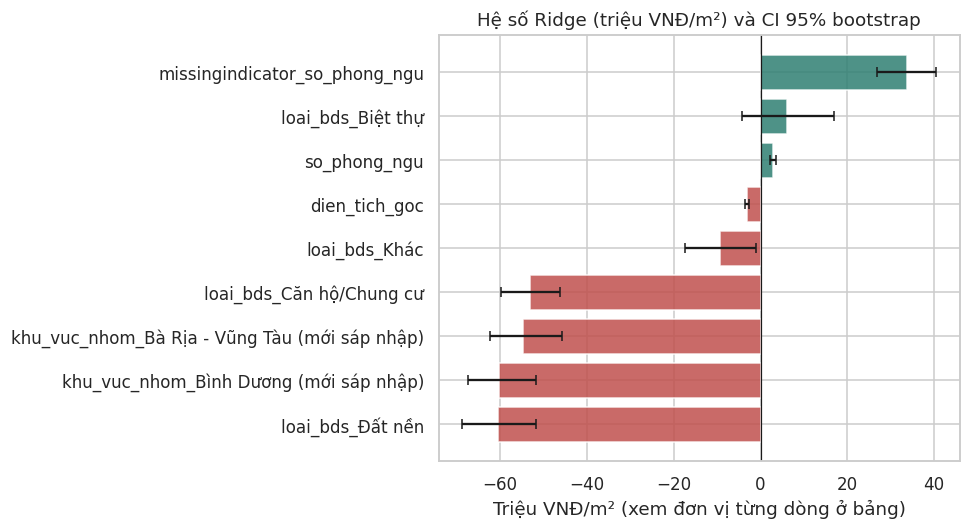

In [3]:
ridge = build_model_pipeline(Ridge(alpha=ridge_alpha)).fit(X_train, y_train)
pre = ridge.named_steps['preprocess']
feat_names = list(pre.get_feature_names_out())
coef = pd.Series(ridge.named_steps['model'].coef_, index=feat_names)

NUM_COLS = NUMERIC_FEATURES + ['missingindicator_so_phong_ngu']   # cột chỉ báo thiếu cũng đi qua StandardScaler
scale = dict(zip(NUM_COLS, pre.named_transformers_['num'].named_steps['scaler'].scale_))
def to_natural_unit(name, value):
    # đổi hệ số trên thang chuẩn hoá về đơn vị tự nhiên
    if name == 'num__dien_tich_goc':
        return value / scale['dien_tich_goc'] * 10, 'mỗi +10 m² diện tích'
    if name == 'num__so_phong_ngu':
        return value / scale['so_phong_ngu'], 'mỗi +1 phòng ngủ'
    if name == 'num__missingindicator_so_phong_ngu':
        return value / scale['missingindicator_so_phong_ngu'], 'tin KHÔNG ghi số phòng ngủ (so với có ghi)'
    return value, 'so với nhóm tham chiếu'

# bootstrap
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(500):
    idx = rng.integers(0, len(X_train), len(X_train))
    m = build_model_pipeline(Ridge(alpha=ridge_alpha)).fit(X_train.iloc[idx], y_train.iloc[idx])
    p = m.named_steps['preprocess']
    c = pd.Series(m.named_steps['model'].coef_, index=list(p.get_feature_names_out()))
    sc = dict(zip(NUM_COLS, p.named_transformers_['num'].named_steps['scaler'].scale_))
    row = {}
    for n, v in c.items():
        if n == 'num__dien_tich_goc': v = v / sc['dien_tich_goc'] * 10
        elif n == 'num__so_phong_ngu': v = v / sc['so_phong_ngu']
        elif n == 'num__missingindicator_so_phong_ngu': v = v / sc['missingindicator_so_phong_ngu']
        row[n] = v
    boot.append(row)
boot = pd.DataFrame(boot).reindex(columns=feat_names)

rows = []
for n, v in coef.items():
    nat, unit = to_natural_unit(n, v)
    lo, hi = np.percentile(boot[n], [2.5, 97.5])
    rows.append({'feature': n, 'y_nghia': unit, 'he_so_trieu_m2': nat / M,
                 'ci95_thap': lo / M, 'ci95_cao': hi / M,
                 'khac_0_95pct': bool(lo > 0 or hi < 0)})
coef_table = pd.DataFrame(rows).sort_values('he_so_trieu_m2', key=np.abs, ascending=False).reset_index(drop=True)
coef_table.to_csv(REPORTS_DIR / 'linear_coefficients.csv', index=False, encoding='utf-8-sig')
display(coef_table.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
plot = coef_table.sort_values('he_so_trieu_m2')
ax.barh(plot['feature'].str.replace('cat__', '').str.replace('num__', ''), plot['he_so_trieu_m2'],
        xerr=[plot['he_so_trieu_m2'] - plot['ci95_thap'], plot['ci95_cao'] - plot['he_so_trieu_m2']],
        color=np.where(plot['he_so_trieu_m2'] >= 0, '#2f7f72', '#c0504d'), alpha=.85, capsize=3)
ax.axvline(0, color='k', lw=.8)
ax.set(title='Hệ số Ridge (triệu VNĐ/m²) và CI 95% bootstrap', xlabel='Triệu VNĐ/m² (xem đơn vị từng dòng ở bảng)')
fig.tight_layout(); fig.savefig(FIGURES_DIR / '09_ridge_coefficients.png', dpi=160, bbox_inches='tight'); plt.show()

**Cách đọc:** hệ số là *quan hệ có điều kiện* trong mô hình tuyến tính (giữ các feature khác không đổi). Hệ số có CI cắt 0 là chưa đủ bằng chứng để khẳng định hướng tác động. Vì VIF lớn nhất chỉ ≈ 1,22 (xem mục 4) nên dấu và độ lớn của hệ số **không bị méo bởi đa cộng tuyến**.

## 3. Importance của mô hình phi tuyến (RandomForest)

Dùng hai góc nhìn và đối chiếu:

1. **Permutation importance** (khuyên dùng): xáo trộn *một feature gốc* ở tập test và đo MAE tăng bao nhiêu. Vì Pipeline nhận DataFrame thô, xáo trộn ngay cột gốc nên **gom đúng theo feature gốc** (không bị tách thành nhiều cột one-hot). 30 lần lặp, `random_state=42`.
2. **Impurity importance** (MDI) gộp theo feature gốc — nhanh nhưng **thiên về biến liên tục** nên chỉ dùng để so sánh, không dùng để kết luận.

Test đã được Mạnh mở để báo cáo cuối, và ở đây không dùng để chọn/tune mô hình; permutation importance trên tập chưa thấy phản ánh đúng mức mô hình *thực sự dựa vào* feature khi dự đoán dữ liệu mới. Làm thêm trên train để kiểm tra tính nhất quán.

,feature,rf_perm_test_mae_tang_trieu,rf_perm_test_std,rf_perm_train_mae_tang_trieu,ridge_perm_test_mae_tang_trieu,rf_impurity_pct,hang_perm_test,hang_impurity,perm_test_pct_tong
0,dien_tich_goc,8.421,0.998,16.810,2.891,52.542,1,1,29.648
1,loai_bds,7.242,0.827,11.884,7.887,19.777,2,2,25.497
2,so_phong_ngu,6.689,0.850,11.216,3.671,13.543,3,4,23.550
3,khu_vuc_nhom,6.051,0.753,7.224,5.309,14.138,4,3,21.304


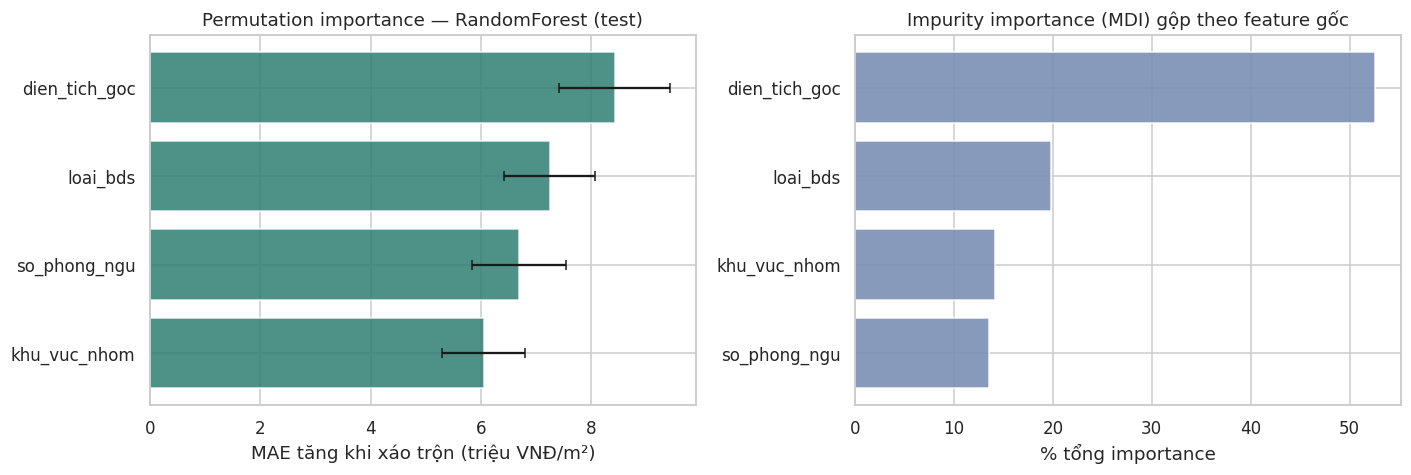

In [4]:
# permutation: mean(MAE sau xáo trộn - MAE gốc) = -(giảm điểm neg_MAE)
rf_test = permutation_importance(rf_model, X_test, y_test, scoring='neg_mean_absolute_error',
                                 n_repeats=30, random_state=RANDOM_STATE, n_jobs=1)
rf_train = permutation_importance(rf_model, X_train, y_train, scoring='neg_mean_absolute_error',
                                  n_repeats=30, random_state=RANDOM_STATE, n_jobs=1)
rd_test = permutation_importance(ridge, X_test, y_test, scoring='neg_mean_absolute_error',
                                 n_repeats=30, random_state=RANDOM_STATE, n_jobs=1)

# impurity importance gộp theo feature gốc
rf_feat = list(rf_model.named_steps['preprocess'].get_feature_names_out())
mdi = pd.Series(rf_model.named_steps['model'].feature_importances_, index=rf_feat)
def origin(n):
    n = n.split('__', 1)[1]
    n = n.replace('missingindicator_', '')
    for f in MODEL_FEATURES:
        if n == f or n.startswith(f + '_'):
            return f
    return n
mdi_group = mdi.groupby(mdi.index.map(origin)).sum()

importance = pd.DataFrame({
    'feature': MODEL_FEATURES,
    'rf_perm_test_mae_tang_trieu': rf_test.importances_mean / M,
    'rf_perm_test_std': rf_test.importances_std / M,
    'rf_perm_train_mae_tang_trieu': rf_train.importances_mean / M,
    'ridge_perm_test_mae_tang_trieu': rd_test.importances_mean / M,
    'rf_impurity_pct': mdi_group.reindex(MODEL_FEATURES).values * 100,
}).sort_values('rf_perm_test_mae_tang_trieu', ascending=False).reset_index(drop=True)
importance['hang_perm_test'] = importance['rf_perm_test_mae_tang_trieu'].rank(ascending=False).astype(int)
importance['hang_impurity'] = importance['rf_impurity_pct'].rank(ascending=False).astype(int)
importance['perm_test_pct_tong'] = importance['rf_perm_test_mae_tang_trieu'] / importance['rf_perm_test_mae_tang_trieu'].sum() * 100
importance.to_csv(REPORTS_DIR / 'importance_table.csv', index=False, encoding='utf-8-sig')
display(importance.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = importance.sort_values('rf_perm_test_mae_tang_trieu')
axes[0].barh(order['feature'], order['rf_perm_test_mae_tang_trieu'], xerr=order['rf_perm_test_std'], color='#2f7f72', alpha=.85, capsize=3)
axes[0].set(title='Permutation importance — RandomForest (test)', xlabel='MAE tăng khi xáo trộn (triệu VNĐ/m²)')
order = importance.sort_values('rf_impurity_pct')
axes[1].barh(order['feature'], order['rf_impurity_pct'], color='#7a8fb5', alpha=.9)
axes[1].set(title='Impurity importance (MDI) gộp theo feature gốc', xlabel='% tổng importance')
fig.tight_layout(); fig.savefig(FIGURES_DIR / '09_rf_importance.png', dpi=160, bbox_inches='tight'); plt.show()

**Điểm cần lưu ý khi đọc:** nếu thứ hạng MDI và permutation khác nhau rõ rệt thì MDI đang bị thiên lệch bởi biến liên tục (`dien_tich_goc` có rất nhiều ngưỡng chia để cây khai thác). Permutation trên dữ liệu chưa thấy là thước đo đáng tin hơn cho câu hỏi “mô hình dựa vào feature nào khi dự đoán tin mới”.

## 4. Đối chiếu với correlation / VIF của Tuấn

Bảng dưới ghép: (a) VIF và Pearson từ `reports/vif_train.csv`, `reports/correlation_train.csv` (tính trên **train**), (b) Spearman tính lại trên train để bắt quan hệ đơn điệu phi tuyến, (c) hạng importance ở mục 3. Mục đích là kiểm tra xem “feature quan trọng” có bị đa cộng tuyến làm méo không và có phù hợp với tương quan thô không.

In [5]:
vif = pd.read_csv(REPORTS_DIR / 'vif_train.csv', encoding='utf-8-sig')
corr = pd.read_csv(REPORTS_DIR / 'correlation_train.csv', encoding='utf-8-sig', index_col=0)
vif['feature_goc'] = vif['feature'].map(origin)
vif_by_feat = vif.groupby('feature_goc')['VIF'].max()

spearman = train_df[['dien_tich_goc', 'so_phong_ngu', TARGET]].corr(method='spearman')[TARGET]
cross = pd.DataFrame({
    'VIF_max_cua_feature': vif_by_feat.reindex(MODEL_FEATURES),
    'pearson_voi_target': corr[TARGET].reindex(MODEL_FEATURES),
    'spearman_voi_target': spearman.reindex(MODEL_FEATURES),
}).join(importance.set_index('feature')[['hang_perm_test', 'hang_impurity', 'rf_perm_test_mae_tang_trieu']])
display(cross.round(3))

# so_phong_ngu thiếu không ngẫu nhiên: tỷ lệ thiếu theo loại BĐS (train)
miss = train_df.groupby('loai_bds')['so_phong_ngu'].agg(ty_le_thieu=lambda s: s.isna().mean(), trung_vi='median', n='size')
display(miss.round(2))
print('Trung vị price_per_m² (triệu) khi CÓ vs KHÔNG ghi số phòng ngủ:')
print((train_df.groupby(train_df['so_phong_ngu'].isna())[TARGET].median() / M).rename({False: 'có ghi', True: 'không ghi'}).round(1).to_string())

,VIF_max_cua_feature,pearson_voi_target,spearman_voi_target,hang_perm_test,hang_impurity,rf_perm_test_mae_tang_trieu
dien_tich_goc,1.219,-0.187,-0.161,1,1,8.421
so_phong_ngu,1.207,0.204,0.455,3,4,6.689
khu_vuc_nhom,1.097,NaN,NaN,4,3,6.051
loai_bds,1.205,NaN,NaN,2,2,7.242


,ty_le_thieu,trung_vi,n
loai_bds,,,
Biệt thự,0.66,5.0,107
Căn hộ/Chung cư,0.36,2.0,368
Khác,0.59,3.0,374
Nhà ở/Nhà phố,0.59,4.0,1598
Đất nền,0.96,4.0,337


Trung vị price_per_m² (triệu) khi CÓ vs KHÔNG ghi số phòng ngủ:
so_phong_ngu
có ghi        97.2
không ghi    101.4


**Đọc đối chiếu:**
- Mọi VIF ≪ 5 → hệ số Ridge và permutation importance không bị chia sẻ/pha loãng bởi đa cộng tuyến; không cần gộp feature trước khi diễn giải.
- Pearson của `dien_tich_goc` với giá/m² chỉ khoảng −0,19 (yếu) nhưng mô hình RandomForest vẫn dùng nó nhiều → quan hệ **không tuyến tính** (giá/m² giảm nhanh khi diện tích nhỏ, phẳng dần khi lớn). bảng giá và lỗi theo khoảng diện tích ở mục 5 làm rõ điều này.
- `so_phong_ngu`: Spearman cao hơn hẳn Pearson, và tỷ lệ thiếu thay đổi mạnh theo `loai_bds` (đất nền gần như luôn thiếu) → thiếu **không ngẫu nhiên**; cờ `missingindicator` mang thông tin về loại tài sản chứ không đơn thuần là “nhiễu thiếu dữ liệu”.

## 5. Lỗi mô hình theo phân khúc

Phân khúc: `khu_vuc_nhom`, `loai_bds`, và khoảng diện tích (ngưỡng cố định theo nghiệp vụ: ≤40, 40–60, 60–80, 80–120, 120–200, >200 m²). Tính trên **test** với mô hình cuối (RandomForest); thêm cột WAPE của Ridge để xem phân khúc nào lỗi do bản chất dữ liệu (cả hai mô hình đều kém) hay do mô hình.

Chỉ số:
- **MAE** (triệu VNĐ/m²): sai số tuyệt đối trung bình — phụ thuộc mặt bằng giá của phân khúc.
- **WAPE** = Σ|lỗi| / Σ giá thực: sai số *tương đối* gộp, so sánh công bằng giữa phân khúc rẻ và đắt. **MdAPE** là trung vị sai số %.
- **Bias** = trung bình (thực tế − dự đoán): dương → mô hình dự đoán thấp hơn giá rao.
- CI 95% của WAPE bằng bootstrap 1.000 lần trong từng phân khúc.

**Quy tắc phân loại (đặt trước khi xem kết quả):** `n < 30` → *không đủ dữ liệu kết luận*; CI WAPE nằm hoàn toàn dưới WAPE chung → *tốt*; nằm hoàn toàn trên → *kém*; còn lại → *tương đương*.

WAPE chung (RF, test): 43.8% | MAE chung: 53.82 triệu VNĐ/m²


,nhom_phan_tich,gia_tri,n,mae_trieu,wape_pct,wape_ci_thap,wape_ci_cao,mdape_pct,bias_trieu,gia_thuc_trung_vi_trieu,wape_ridge_pct,danh_gia
0,Khu vực,Bà Rịa - Vũng Tàu (mới sáp nhập),29,28.79,65.68,45.82,93.96,93.44,-16.76,34.29,77.54,không đủ dữ liệu (n<30)
1,Khu vực,Bình Dương (mới sáp nhập),49,20.95,46.31,34.12,60.96,29.80,-2.90,45.00,64.06,tương đương
2,Khu vực,TP.HCM (lõi cũ),618,57.60,43.39,40.38,46.59,35.30,4.74,112.02,44.67,tương đương
3,Loại BĐS,Biệt thự,35,43.79,38.35,28.87,49.71,33.06,-0.55,100.00,45.59,tương đương
4,Loại BĐS,Căn hộ/Chung cư,97,32.48,49.29,41.23,57.98,38.89,-1.33,52.94,52.05,tương đương
5,Loại BĐS,Khác,97,46.89,40.27,34.07,47.89,33.44,-2.99,110.32,46.91,tương đương
6,Loại BĐS,Nhà ở/Nhà phố,394,64.07,42.95,39.20,46.55,34.20,6.34,128.04,43.60,tương đương
7,Loại BĐS,Đất nền,73,40.86,58.74,49.33,69.71,59.12,3.27,60.00,58.73,kém
8,Khoảng diện tích,≤40 m²,76,67.50,37.91,30.03,46.40,27.58,11.96,174.60,41.47,tương đương
9,Khoảng diện tích,40–60 m²,137,56.24,43.73,37.12,50.82,30.62,15.62,105.00,49.23,tương đương


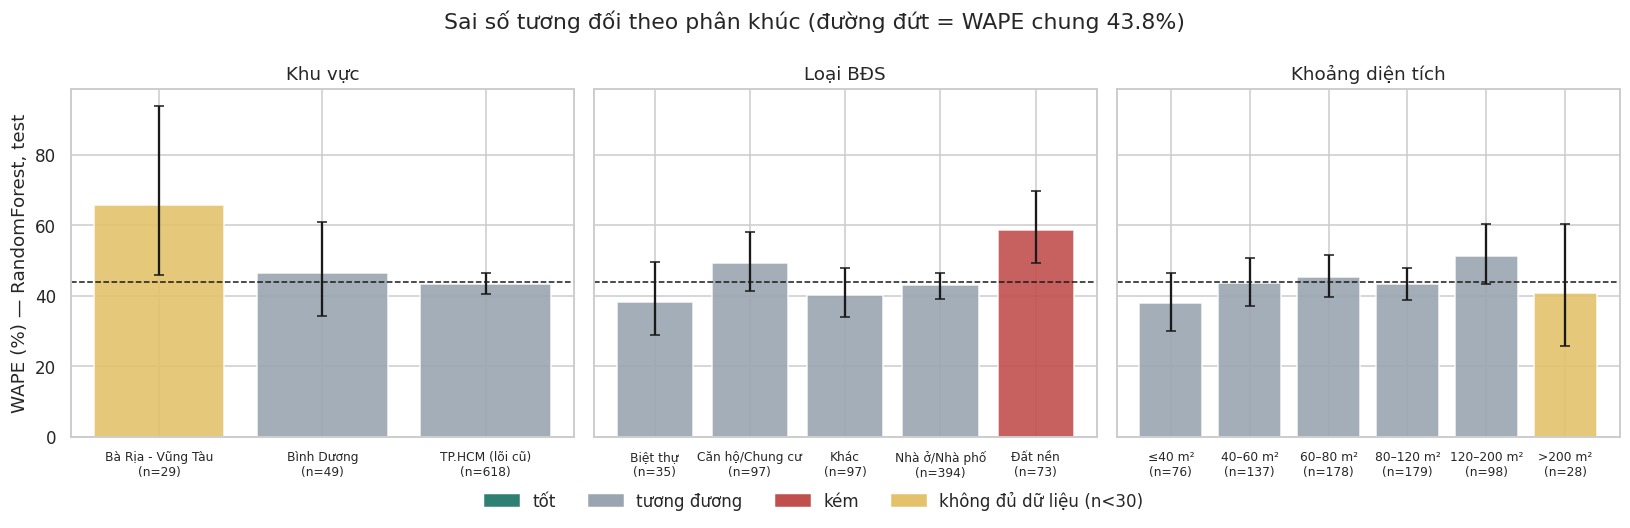

In [6]:
seg_df = test_df.copy()
seg_df['pred_rf'] = rf_pred
seg_df['pred_ridge'] = ridge.predict(X_test)
seg_df['khoang_dien_tich'] = pd.cut(seg_df['dien_tich_goc'], [0, 40, 60, 80, 120, 200, 2000],
                                    labels=['≤40 m²', '40–60 m²', '60–80 m²', '80–120 m²', '120–200 m²', '>200 m²'])
y = seg_df[TARGET].to_numpy()
overall_wape = np.abs(y - seg_df['pred_rf']).sum() / y.sum() * 100
print(f'WAPE chung (RF, test): {overall_wape:.1f}% | MAE chung: {mean_absolute_error(y, seg_df.pred_rf)/M:.2f} triệu VNĐ/m²')

def boot_wape(yv, pv, n_boot=1000, seed=RANDOM_STATE):
    r = np.random.default_rng(seed)
    out = np.empty(n_boot)
    for i in range(n_boot):
        k = r.integers(0, len(yv), len(yv))
        out[i] = np.abs(yv[k] - pv[k]).sum() / yv[k].sum() * 100
    return np.percentile(out, [2.5, 97.5])

def classify(n, lo, hi):
    if n < 30: return 'không đủ dữ liệu (n<30)'
    if hi < overall_wape: return 'tốt'
    if lo > overall_wape: return 'kém'
    return 'tương đương'

seg_rows = []
for col, label in [('khu_vuc_nhom', 'Khu vực'), ('loai_bds', 'Loại BĐS'), ('khoang_dien_tich', 'Khoảng diện tích')]:
    for val, g in seg_df.groupby(col, observed=True):
        yv, pv, pr = g[TARGET].to_numpy(), g['pred_rf'].to_numpy(), g['pred_ridge'].to_numpy()
        lo, hi = boot_wape(yv, pv)
        res = yv - pv
        seg_rows.append({
            'nhom_phan_tich': label, 'gia_tri': str(val), 'n': len(g),
            'mae_trieu': np.abs(res).mean() / M,
            'wape_pct': np.abs(res).sum() / yv.sum() * 100,
            'wape_ci_thap': lo, 'wape_ci_cao': hi,
            'mdape_pct': np.median(np.abs(res) / yv) * 100,
            'bias_trieu': res.mean() / M,
            'gia_thuc_trung_vi_trieu': np.median(yv) / M,
            'wape_ridge_pct': np.abs(yv - pr).sum() / yv.sum() * 100,
            'danh_gia': classify(len(g), lo, hi),
        })
error_by_segment = pd.DataFrame(seg_rows)
error_by_segment.to_csv(REPORTS_DIR / 'error_by_segment.csv', index=False, encoding='utf-8-sig')
display(error_by_segment.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
palette = {'tốt': '#2f7f72', 'tương đương': '#9aa5b1', 'kém': '#c0504d', 'không đủ dữ liệu (n<30)': '#e3c26b'}
for ax, (label, g) in zip(axes, error_by_segment.groupby('nhom_phan_tich', sort=False)):
    g = g.reset_index(drop=True)
    ax.bar(range(len(g)), g['wape_pct'], color=g['danh_gia'].map(palette),
           yerr=[g['wape_pct'] - g['wape_ci_thap'], g['wape_ci_cao'] - g['wape_pct']], capsize=3, alpha=.9)
    ax.axhline(overall_wape, color='k', ls='--', lw=1)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([f"{v}\n(n={n})" for v, n in zip(g['gia_tri'].str.replace(' (mới sáp nhập)', '', regex=False), g['n'])], fontsize=8, rotation=0)
    ax.set_title(label)
axes[0].set_ylabel('WAPE (%) — RandomForest, test')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
fig.legend(handles, palette.keys(), loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle(f'Sai số tương đối theo phân khúc (đường đứt = WAPE chung {overall_wape:.1f}%)')
fig.tight_layout(); fig.savefig(FIGURES_DIR / '09_error_by_segment.png', dpi=160, bbox_inches='tight'); plt.show()

### 5.1 Vì sao nhóm kém/tốt? — kiểm tra giải thích bằng dữ liệu

Không suy diễn từ trực giác: bảng dưới đo (trên **train**, nơi mô hình học) mức độ **phân tán giá/m² trong từng phân khúc** (hệ số biến thiên CV = std/mean) và **tỷ lệ thiếu số phòng ngủ**. Phân khúc có giá phân tán lớn hoặc thiếu thông tin thì khó dự đoán hơn bất kể mô hình.

In [7]:
def describe_segments(col, bins=None):
    d = train_df.copy()
    if bins is not None:
        d[col] = pd.cut(d['dien_tich_goc'], [0, 40, 60, 80, 120, 200, 2000], labels=bins)
    out = d.groupby(col, observed=True).agg(
        n_train=(TARGET, 'size'),
        gia_trung_vi_trieu=(TARGET, lambda s: s.median() / M),
        he_so_bien_thien=(TARGET, lambda s: s.std() / s.mean()),
        ty_le_thieu_phong_ngu=('so_phong_ngu', lambda s: s.isna().mean()),
    )
    return out

for col, bins in [('khu_vuc_nhom', None), ('loai_bds', None),
                  ('khoang_dien_tich', ['≤40 m²', '40–60 m²', '60–80 m²', '80–120 m²', '120–200 m²', '>200 m²'])]:
    print(f'--- {col}')
    display(describe_segments(col, bins).round(2))

print('Giá/m² trung vị (triệu) theo loại BĐS × khu vực (train):')
display((train_df.pivot_table(index='loai_bds', columns='khu_vuc_nhom', values=TARGET, aggfunc='median') / M).round(1))
print('Số tin (train):')
display(train_df.pivot_table(index='loai_bds', columns='khu_vuc_nhom', values=TARGET, aggfunc='size').fillna(0).astype(int))

# Hiệu chỉnh: mô hình có "co về trung bình" không? (nhóm theo GIÁ DỰ ĐOÁN, không theo giá thực)
seg_df['nhom_gia_du_doan'] = pd.qcut(seg_df['pred_rf'], 5, labels=['Q1 thấp', 'Q2', 'Q3', 'Q4', 'Q5 cao'])
calib = seg_df.groupby('nhom_gia_du_doan', observed=True).agg(
    n=('pred_rf', 'size'), du_doan_tb_trieu=('pred_rf', lambda s: s.mean() / M),
    thuc_te_tb_trieu=(TARGET, lambda s: s.mean() / M))
calib['thuc_te_tru_du_doan'] = calib['thuc_te_tb_trieu'] - calib['du_doan_tb_trieu']
print('Hiệu chỉnh theo nhóm giá dự đoán (test):')
display(calib.round(1))

abs_err = np.abs(y - seg_df['pred_rf']).sort_values(ascending=False)
for share in (0.05, 0.10):
    k = int(len(abs_err) * share)
    print(f'{share:.0%} tin sai nhiều nhất chiếm {abs_err.head(k).sum() / abs_err.sum():.1%} tổng sai số tuyệt đối')

--- khu_vuc_nhom


,n_train,gia_trung_vi_trieu,he_so_bien_thien,ty_le_thieu_phong_ngu
khu_vuc_nhom,,,,
Bà Rịa - Vũng Tàu (mới sáp nhập),113,41.11,0.97,0.76
Bình Dương (mới sáp nhập),220,48.17,0.89,0.64
TP.HCM (lõi cũ),2451,110.42,0.71,0.60


--- loai_bds


,n_train,gia_trung_vi_trieu,he_so_bien_thien,ty_le_thieu_phong_ngu
loai_bds,,,,
Biệt thự,107,113.64,0.49,0.66
Căn hộ/Chung cư,368,51.84,0.79,0.36
Khác,374,112.39,0.68,0.59
Nhà ở/Nhà phố,1598,117.94,0.68,0.59
Đất nền,337,49.54,1.02,0.96


--- khoang_dien_tich


,n_train,gia_trung_vi_trieu,he_so_bien_thien,ty_le_thieu_phong_ngu
khoang_dien_tich,,,,
≤40 m²,256,156.96,0.69,0.54
40–60 m²,678,93.20,0.78,0.51
60–80 m²,637,106.06,0.72,0.55
80–120 m²,648,95.07,0.74,0.67
120–200 m²,358,94.70,0.72,0.73
>200 m²,207,75.85,0.67,0.83


... (3 outputs left out)

khu_vuc_nhom,Bà Rịa - Vũng Tàu (mới sáp nhập),Bình Dương (mới sáp nhập),TP.HCM (lõi cũ)
loai_bds,,,
Biệt thự,6,3,98
Căn hộ/Chung cư,14,93,261
Khác,23,47,304
Nhà ở/Nhà phố,32,51,1515
Đất nền,38,26,273


Hiệu chỉnh theo nhóm giá dự đoán (test):


,n,du_doan_tb_trieu,thuc_te_tb_trieu,thuc_te_tru_du_doan
nhom_gia_du_doan,,,,
Q1 thấp,140,50.7,52.6,1.9
Q2,139,86.2,93.7,7.5
Q3,139,120.6,123.2,2.6
Q4,139,149.6,155.5,5.9
Q5 cao,139,191.3,189.9,-1.4


5% tin sai nhiều nhất chiếm 21.3% tổng sai số tuyệt đối
10% tin sai nhiều nhất chiếm 33.5% tổng sai số tuyệt đối


**Kết luận kỹ thuật từ mục 5** được tổng hợp ở mục 7 sau khi có đủ bằng chứng; điểm cần nhớ ở đây là mọi so sánh dùng *sai số tương đối* và có CI, và các phân khúc nhỏ (n<30) chỉ mang tính tham khảo.

## 6. Đề xuất feature mới — chỉ giữ khi CV chứng minh

Vai trò Feature Engineering kế thừa từ Bài 3. Contract hiện tại của Tuấn mới có 4 feature và ghi `vi_tri`/`tieu_de` là *FORBIDDEN_CURRENT* vì (i) 143 phường/xã không one-hot trực tiếp được và (ii) chưa có NLP pipeline kiểm chứng. Mục này kiểm tra **có nên mở contract hay không**, bằng bằng chứng, không bằng cảm tính.

**Ứng viên** (đều chỉ dùng thông tin có sẵn lúc đăng tin, không dùng giá):

| Ứng viên | Cách tạo | Chống leakage |
|---|---|---|
| `log_dien_tich` | log(`dien_tich_goc`) | phép biến đổi từng dòng |
| `dt_per_pn` | diện tích / số phòng ngủ (thiếu → median; sàn 1) | phép biến đổi từng dòng; median fit trong fold |
| `mat_tien`, `hem`, `so_hong` | cờ 0/1 từ từ khoá trong tiêu đề (“mặt tiền”, “hẻm/ngõ”, “sổ hồng/đỏ”) | phép biến đổi từng dòng, không học từ target |
| `phuong_xa` (TargetEncoder) | tên phường/xã (token đầu của `vi_tri`) → trung bình target có làm mượt | `TargetEncoder` nằm **trong Pipeline**, cross-fitting nội bộ, fit lại ở mỗi fold |

**Quy tắc giữ:** với cùng 5 fold của Mạnh, tính *chênh lệch MAE theo cặp fold* so với baseline. Giữ nếu chênh lệch trung bình < 0 **và** |trung bình| ≥ 2 sai số chuẩn của chênh lệch (`qua_quy_tac_cv`, đặt trước khi chạy) **và** cải thiện vẫn còn khi dùng GroupKFold (chống tin đăng trùng nội dung). Test không tham gia quyết định.

*Bổ sung minh bạch:* sau khi chạy thấy vài feature đạt 2 SE nhưng chỉ giảm MAE < 1% (ví dụ `log_dien_tich` cho Ridge, giảm 0,86%) — có ý nghĩa thống kê nhưng không đáng thêm độ phức tạp. Vì vậy thêm tiêu chí **ý nghĩa thực tiễn: giảm ≥ 1% MAE** (`dang_ke_thuc_te`). Tiêu chí này được thêm *sau* khi xem kết quả nên được ghi rõ ở đây; kết luận về `phuong_xa` không phụ thuộc vào nó (giảm ~28%).

In [8]:
import re
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder

def add_candidate_features(df):
    d = df.copy()
    d['log_dien_tich'] = np.log(d['dien_tich_goc'])
    d['phuong_xa'] = d['vi_tri'].astype(str).str.split(',').str[0].str.strip()
    t = d['tieu_de'].fillna('').str.lower()
    d['mat_tien'] = t.str.contains(r'mặt tiền|\bmt\b|mặt phố|mặt đường', regex=True).astype(float)
    d['hem'] = t.str.contains(r'hẻm|\bhem\b|ngõ', regex=True).astype(float)
    d['so_hong'] = t.str.contains(r'sổ hồng|sổ đỏ|\bshr?\b', regex=True).astype(float)
    pn = d['so_phong_ngu']
    d['dt_per_pn'] = d['dien_tich_goc'] / pn.fillna(pn.median()).clip(lower=1)
    return d

def make_candidate_pipeline(estimator, extra_num=(), extra_te=(), extra_bin=()):
    num = Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True)), ('scaler', StandardScaler())])
    cat = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                    ('onehot', OneHotEncoder(handle_unknown='ignore', drop=CATEGORY_REFERENCE_LEVELS, sparse_output=False))])
    transformers = [('num', num, NUMERIC_FEATURES + list(extra_num)), ('cat', cat, CATEGORICAL_FEATURES)]
    if extra_te:
        transformers.append(('te', TargetEncoder(target_type='continuous', smooth='auto', random_state=RANDOM_STATE), list(extra_te)))
    if extra_bin:
        transformers.append(('bin', 'passthrough', list(extra_bin)))
    return Pipeline([('add', FunctionTransformer(add_candidate_features)),
                     ('pre', ColumnTransformer(transformers, remainder='drop')),
                     ('model', estimator)])

CAND_COLS = MODEL_FEATURES + ['vi_tri', 'tieu_de']   # chỉ để TẠO feature; giá không có mặt
Xc_train, Xc_test = train_df[CAND_COLS], test_df[CAND_COLS]
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # cùng CV với Mạnh

make_rf = lambda: RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1, **{k.replace('model__', ''): v for k, v in rf_params.items()})
make_ridge = lambda: Ridge(alpha=ridge_alpha)
FLAGS = ['mat_tien', 'hem', 'so_hong']
candidates = {
    'baseline': {},
    '+log_dien_tich': dict(extra_num=['log_dien_tich']),
    '+dt_per_pn': dict(extra_num=['dt_per_pn']),
    '+mat_tien': dict(extra_bin=['mat_tien']),
    '+hem': dict(extra_bin=['hem']),
    '+so_hong': dict(extra_bin=['so_hong']),
    '+phuong_xa (TE)': dict(extra_te=['phuong_xa']),
    '+phuong_xa (TE) + 3 cờ tiêu đề': dict(extra_te=['phuong_xa'], extra_bin=FLAGS),
}
print('Tỷ lệ tin có cờ (train):', (add_candidate_features(train_df)[FLAGS].mean() * 100).round(1).to_dict(), '| số phường/xã:', add_candidate_features(train_df)['phuong_xa'].nunique())

cand_rows = []
for model_name, factory in [('Ridge', make_ridge), ('RandomForest', make_rf)]:
    base_scores = None
    for cname, kw in candidates.items():
        scores = -cross_val_score(make_candidate_pipeline(factory(), **kw), Xc_train, y_train,
                                  cv=cv, scoring='neg_mean_absolute_error', n_jobs=1)
        if cname == 'baseline':
            base_scores = scores
        diff = scores - base_scores
        se = diff.std(ddof=1) / np.sqrt(len(diff)) if cname != 'baseline' else np.nan
        cand_rows.append({'mo_hinh': model_name, 'ung_vien': cname, 'cv_mae_trieu': scores.mean() / M,
                          'chenh_lech_vs_baseline_trieu': diff.mean() / M, 'se_chenh_lech_trieu': se / M if cname != 'baseline' else np.nan,
                          'so_se': (-diff.mean() / se) if cname != 'baseline' else np.nan,
                          'giam_pct': -diff.mean() / base_scores.mean() * 100})
cand_table = pd.DataFrame(cand_rows)
cand_table['qua_quy_tac_cv'] = (cand_table['chenh_lech_vs_baseline_trieu'] < 0) & (cand_table['so_se'] >= 2)
cand_table['dang_ke_thuc_te'] = cand_table['giam_pct'] >= 1.0      # bổ sung sau khi xem kết quả, xem giải thích bên dưới
cand_table['de_xuat_giu'] = cand_table['qua_quy_tac_cv'] & cand_table['dang_ke_thuc_te']
display(cand_table.round(3))

Tỷ lệ tin có cờ (train): {'mat_tien': 20.0, 'hem': 15.2, 'so_hong': 7.0} | số phường/xã: 143


,mo_hinh,ung_vien,cv_mae_trieu,chenh_lech_vs_baseline_trieu,se_chenh_lech_trieu,so_se,giam_pct,qua_quy_tac_cv,dang_ke_thuc_te,de_xuat_giu
0,Ridge,baseline,56.624,0.000,NaN,NaN,-0.000,False,False,False
1,Ridge,+log_dien_tich,56.138,-0.486,0.070,6.970,0.858,True,False,False
2,Ridge,+dt_per_pn,56.646,0.022,0.036,-0.622,-0.040,False,False,False
3,Ridge,+mat_tien,55.658,-0.966,0.620,1.560,1.707,False,True,False
4,Ridge,+hem,56.575,-0.049,0.112,0.437,0.086,False,False,False
5,Ridge,+so_hong,56.107,-0.517,0.158,3.268,0.914,True,False,False
6,Ridge,+phuong_xa (TE),42.589,-14.035,0.729,19.254,24.786,True,True,True
7,Ridge,+phuong_xa (TE) + 3 cờ tiêu đề,41.694,-14.930,0.839,17.793,26.366,True,True,True
8,RandomForest,baseline,51.675,0.000,NaN,NaN,-0.000,False,False,False
9,RandomForest,+log_dien_tich,51.582,-0.093,0.085,1.093,0.180,False,False,False


### 6.1 Kiểm tra độ bền của cải thiện

Hai mối lo thực tế với dữ liệu tin rao: (1) cùng một căn nhà bị đăng nhiều lần dưới link khác nhau → `KFold` thường có thể “nhìn thấy” bản sao ở fold validation và làm CV lạc quan, đặc biệt với `TargetEncoder` theo phường; (2) cải thiện chỉ nằm ở nhóm tin trùng. Kiểm tra bằng cách nhóm các tin có cùng (`gia_goc`, `dien_tich_goc`, `vi_tri`) vào cùng một nhóm cho `GroupKFold`, và so sánh lỗi test giữa tin có/không có bản sao trong train.

In [9]:
key_cols = ['gia_goc', 'dien_tich_goc', 'vi_tri']
mk = lambda d: d[key_cols].astype(str).agg('|'.join, axis=1)
train_key, test_key = mk(train_df), mk(test_df)
groups = train_key.factorize()[0]
print(f'Train: {len(train_df):,} tin thuộc {train_key.nunique():,} nhóm trùng (giá, diện tích, vị trí) → {len(train_df) - train_key.nunique()} bản sao còn sót')
print(f'Test: {test_key.isin(set(train_key)).sum()}/{len(test_df)} tin có bản sao trong train')

gkf = GroupKFold(n_splits=5)
robust_rows = []
for cname in ['baseline', '+mat_tien', '+hem', '+so_hong', '+phuong_xa (TE)', '+phuong_xa (TE) + 3 cờ tiêu đề']:
    s = -cross_val_score(make_candidate_pipeline(make_rf(), **candidates[cname]), Xc_train, y_train,
                         cv=gkf, groups=groups, scoring='neg_mean_absolute_error', n_jobs=1)
    robust_rows.append({'ung_vien': cname, 'rf_cv_mae_groupkfold_trieu': s.mean() / M})
robust = pd.DataFrame(robust_rows)
robust['giam_vs_baseline_pct'] = (1 - robust['rf_cv_mae_groupkfold_trieu'] / robust.loc[0, 'rf_cv_mae_groupkfold_trieu']) * 100
display(robust.round(3))

Train: 2,784 tin thuộc 2,637 nhóm trùng (giá, diện tích, vị trí) → 147 bản sao còn sót
Test: 43/696 tin có bản sao trong train


,ung_vien,rf_cv_mae_groupkfold_trieu,giam_vs_baseline_pct
0,baseline,52.455,0.000
1,+mat_tien,50.838,3.081
2,+hem,52.300,0.296
3,+so_hong,52.041,0.788
4,+phuong_xa (TE),38.096,27.374
5,+phuong_xa (TE) + 3 cờ tiêu đề,36.421,30.567


### 6.2 Xác nhận một lần trên test (không dùng để chọn)

Quyết định giữ/bỏ feature **đã chốt ở trên bằng CV**. Bước này chỉ *xác nhận* một lần trên test cho baseline và các cấu hình được giữ, và tách tin có/không có bản sao trong train. Đây không phải mô hình chính thức: nếu nhóm chấp nhận đề xuất, Tuấn cập nhật contract/preprocess và Mạnh huấn luyện + tune lại theo đúng quy trình (test chỉ mở một lần cuối).

In [10]:
kept = cand_table[(cand_table['mo_hinh'] == 'RandomForest') & cand_table['de_xuat_giu']]['ung_vien'].tolist()
confirm_names = ['baseline'] + [c for c in ['+phuong_xa (TE)', '+phuong_xa (TE) + 3 cờ tiêu đề'] if c in kept]
has_copy = test_key.isin(set(train_key)).to_numpy()
confirm_rows = []
for cname in confirm_names:
    m = make_candidate_pipeline(make_rf(), **candidates[cname]).fit(Xc_train, y_train)
    p = m.predict(Xc_test)
    ae = np.abs(y_test.to_numpy() - p)
    confirm_rows.append({'cau_hinh': cname, 'test_mae_trieu': ae.mean() / M,
                         'test_mae_tin_co_ban_sao': ae[has_copy].mean() / M,
                         'test_mae_tin_khong_ban_sao': ae[~has_copy].mean() / M,
                         'test_r2': 1 - ((y_test.to_numpy() - p) ** 2).sum() / ((y_test.to_numpy() - y_test.mean()) ** 2).sum()})
confirm = pd.DataFrame(confirm_rows)
display(confirm.round(3))

cand_out = cand_table.merge(robust.rename(columns={'rf_cv_mae_groupkfold_trieu': 'rf_groupkfold_mae_trieu'}), on='ung_vien', how='left')
cand_out.loc[cand_out['mo_hinh'] != 'RandomForest', ['rf_groupkfold_mae_trieu', 'giam_vs_baseline_pct']] = np.nan
cand_out.to_csv(REPORTS_DIR / 'feature_candidates_cv.csv', index=False, encoding='utf-8-sig')
confirm.to_csv(REPORTS_DIR / 'feature_candidates_test_confirmation.csv', index=False, encoding='utf-8-sig')
print('Ứng viên đề xuất giữ (RandomForest, qua quy tắc CV + đáng kể thực tế):', kept)

,cau_hinh,test_mae_trieu,test_mae_tin_co_ban_sao,test_mae_tin_khong_ban_sao,test_r2
0,baseline,53.819,51.775,53.954,0.247
1,+phuong_xa (TE),38.212,39.349,38.138,0.569
2,+phuong_xa (TE) + 3 cờ tiêu đề,37.360,39.467,37.221,0.586


Ứng viên đề xuất giữ (RandomForest, qua quy tắc CV + đáng kể thực tế): ['+mat_tien', '+so_hong', '+phuong_xa (TE)', '+phuong_xa (TE) + 3 cờ tiêu đề']


### 6.3 Feature mới thay đổi lỗi theo phân khúc thế nào?

Nếu `phuong_xa` thực sự bổ sung thông tin địa lý, phân khúc **Bà Rịa–Vũng Tàu / Bình Dương** (nơi nhóm khu vực 3-mức quá thô) phải cải thiện rõ nhất. Đây là bài kiểm tra “lý do cải thiện có hợp lý không”, giúp tránh tin vào một con số CV mà không giải thích được.

,nhom,gia_tri,n,wape_hien_tai_pct,wape_them_phuong_xa_pct,giam_diem_pct
0,Khu vực,Bà Rịa - Vũng Tàu (mới sáp nhập),29,65.7,46.9,18.8
1,Khu vực,Bình Dương (mới sáp nhập),49,46.3,40.7,5.6
2,Khu vực,TP.HCM (lõi cũ),618,43.4,30.6,12.8
3,Loại BĐS,Biệt thự,35,38.3,22.4,16.0
4,Loại BĐS,Căn hộ/Chung cư,97,49.3,42.5,6.8
5,Loại BĐS,Khác,97,40.3,29.8,10.5
6,Loại BĐS,Nhà ở/Nhà phố,394,43.0,30.4,12.5
7,Loại BĐS,Đất nền,73,58.7,34.5,24.3
8,Khoảng diện tích,≤40 m²,76,37.9,29.5,8.4
9,Khoảng diện tích,40–60 m²,137,43.7,33.2,10.6


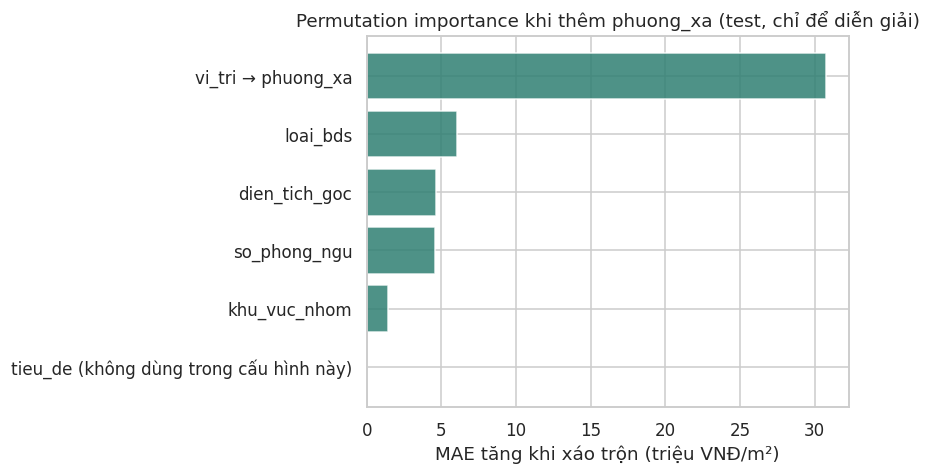

In [11]:
best_cfg = '+phuong_xa (TE)'
m_new = make_candidate_pipeline(make_rf(), **candidates[best_cfg]).fit(Xc_train, y_train)
seg_df['pred_new'] = m_new.predict(Xc_test)
rows = []
for col, label in [('khu_vuc_nhom', 'Khu vực'), ('loai_bds', 'Loại BĐS'), ('khoang_dien_tich', 'Khoảng diện tích')]:
    for val, g in seg_df.groupby(col, observed=True):
        yv = g[TARGET].to_numpy()
        w0 = np.abs(yv - g['pred_rf']).sum() / yv.sum() * 100
        w1 = np.abs(yv - g['pred_new']).sum() / yv.sum() * 100
        rows.append({'nhom': label, 'gia_tri': str(val), 'n': len(g), 'wape_hien_tai_pct': w0, 'wape_them_phuong_xa_pct': w1, 'giam_diem_pct': w0 - w1})
seg_new = pd.DataFrame(rows)
display(seg_new.round(1))
seg_new.to_csv(REPORTS_DIR / 'error_by_segment_with_phuong_xa.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(8, 4.5))
imp_new = permutation_importance(m_new, Xc_test, y_test, scoring='neg_mean_absolute_error', n_repeats=20, random_state=RANDOM_STATE, n_jobs=1)
imp_new = pd.Series(imp_new.importances_mean / M, index=[{'vi_tri': 'vi_tri → phuong_xa', 'tieu_de': 'tieu_de (không dùng trong cấu hình này)'}.get(c, c) for c in CAND_COLS]).sort_values()
ax.barh(imp_new.index, imp_new.values, color='#2f7f72', alpha=.85)
ax.set(title='Permutation importance khi thêm phuong_xa (test, chỉ để diễn giải)', xlabel='MAE tăng khi xáo trộn (triệu VNĐ/m²)')
fig.tight_layout(); fig.savefig(FIGURES_DIR / '09_importance_with_phuong_xa.png', dpi=160, bbox_inches='tight'); plt.show()

## 7. Kết luận nghiệp vụ (có bằng chứng)

Đầy đủ, kèm bảng số liệu và việc cần phối hợp: `reports/model_findings.md`. Tóm tắt:

**1. Loại tài sản và vùng quyết định mặt bằng giá/m² nhiều hơn quy mô.**
Ridge (giữ các biến khác không đổi): đất nền thấp hơn nhà phố ≈ **60,5 triệu/m²** (CI 95%: −68,7 đến −51,7); Bình Dương thấp hơn TP.HCM lõi cũ ≈ **60,3** (−67,4 đến −51,8); Bà Rịa–Vũng Tàu ≈ **54,9**; căn hộ ≈ **53,2** so với nhà phố. Biệt thự **chưa có bằng chứng** khác nhà phố (CI cắt 0). Bảng trung vị theo loại × vùng cho cùng bức tranh: đất nền BR–VT ≈ 8,6 triệu/m² so với ≈ 58,1 triệu/m² ở TP.HCM.

**2. Vị trí chi tiết cấp phường/xã là thông tin còn thiếu lớn nhất của mô hình.**
Thêm `phuong_xa` (target encoding trong Pipeline) giảm CV MAE của RandomForest từ **51,7 → 37,4 triệu/m² (−27,6%)**; GroupKFold chống tin trùng vẫn giảm **27,4%**; xác nhận một lần trên test: MAE **53,8 → 38,2**, R² **0,25 → 0,57**, và cải thiện vẫn nguyên với các tin không có bản sao. Nhóm khu vực 3 mức hiện tại quá thô để định giá.

**3. Đất nền là loại tin mô hình dự đoán kém nhất.**
WAPE đất nền **58,7%** (CI 49,3–69,7) so với **43,8%** chung — nhóm duy nhất có CI nằm hoàn toàn trên mức chung. Nguyên nhân khớp dữ liệu: giá phân tán cao nhất (hệ số biến thiên 1,02), 96% tin không ghi số phòng ngủ (gần như không có thông tin mô tả) và giá thay đổi mạnh theo vùng. Thêm `phuong_xa` giảm WAPE đất nền xuống **34,5%** (−24 điểm, lớn nhất). Chú ý: nếu chỉ nhìn MAE thì *nhà phố* có vẻ tệ nhất (64,1 triệu) — đó là hiệu ứng mặt bằng giá, không phải độ chính xác kém.

**4. Diện tích nhỏ có đơn giá/m² cao hơn; số phòng ngủ và việc “không ghi phòng ngủ” đều mang thông tin.**
Mỗi **+10 m²** diện tích, giá/m² giảm ≈ **3,2 triệu** (CI −3,7 đến −2,7); trung vị train ≤40 m² là ≈ 157 triệu/m² so với ≈ 76 triệu/m² ở >200 m². Mô hình **dự đoán thấp** cho căn nhỏ (bias +12 đến +16 triệu ở nhóm ≤60 m²). Mỗi **+1 phòng ngủ** ≈ +2,8 triệu; tin **không ghi** phòng ngủ có đơn giá cao hơn ≈ 33,7 triệu *sau khi kiểm soát loại BĐS* — thiếu không ngẫu nhiên, không nên coi là nhiễu thuần tuý.

**5. Mô hình hiện tại chỉ nên dùng làm khoảng tham chiếu, chưa phải định giá.**
R² test 0,25; sai số tương đối gộp 43,8%; 5% tin sai nhiều nhất chiếm 21,3% tổng sai số. Phần lớn phân khúc **không** tách được khỏi mức chung (CI rộng, test chỉ 696 tin) nên không nên khẳng định loại/khu vực nào “chính xác hơn” ngoài đất nền.

> Mọi kết luận là quan hệ **dự báo** trên giá rao (không phải giá giao dịch) của một snapshot; không suy ra nhân quả.

## 8. Việc cần phối hợp với các thành viên

| Với | Đề xuất | Lý do |
|---|---|---|
| **Tuấn** | Mở `feature_contract.csv`: cho phép `phuong_xa` (tách từ `vi_tri`, **target-encode trong Pipeline**) và cân nhắc cờ `mat_tien`; khử trùng theo nội dung (`gia_goc`, `dien_tich_goc`, `vi_tri`) | Mục 6: giảm CV MAE ~28%; 147 bản sao còn sót trong train, 43 tin test có bản sao trong train |
| **Mạnh** | Nếu Tuấn chấp nhận: tune/chọn lại với feature mới theo đúng quy trình (CV, test mở một lần). Số test ở mục 6.2 chỉ là xác nhận, **không phải kết quả chính thức** | Tránh “nhìn test để chọn” |
| **Quí** | Nếu mô hình mới được chọn: app cần ô chọn phường/xã (+ checkbox mặt tiền); thông báo giới hạn: dùng như khoảng tham chiếu | Mục 5, kết luận 5 |
| **Việt** | Đưa kết luận 1–5 và các hạn chế (giá rao ≠ giá giao dịch; snapshot; nhóm khu vực thô; thiếu không ngẫu nhiên; không nhân quả) vào báo cáo | Số liệu ở `reports/model_findings.md` |
| **Long** | Thêm `seaborn` vào `requirements.txt`; yêu cầu `scikit-learn>=1.4` (TargetEncoder) nếu dùng `phuong_xa` | Notebook 09 dùng seaborn; TargetEncoder có từ scikit-learn 1.3 |

*Chạy lại:* notebook chạy được từ thư mục gốc hoặc `notebooks/`; mọi bảng/hình được ghi vào `reports/` và `reports/figures/` (tiền tố `09_`). Số liệu trong văn bản được tạo trên scikit-learn 1.8.0 và khớp `model_comparison.csv` của Mạnh đến chữ số thập phân; các bản scikit-learn khác có thể lệch nhẹ ở phần thập phân của bước bootstrap/CV.